## Importing Required Libraries

In [1]:
import os
import time
import pickle

from tqdm import tqdm

import xml.etree.ElementTree as ET
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers

In [2]:
# Check the dataset folders



file_path = "/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final"

print(os.listdir(file_path))

['annotations', 'images']


In [3]:
# Check one XML annotation

xml_path = "/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/annotations/test/VOC2007_000010.xml"
print(open(xml_path).read())

<annotation>
	<folder>VOC2007</folder>
	<filename>000010.jpg</filename>
	<source>
		<database>The VOC2007 Database</database>
		<annotation>PASCAL VOC2007</annotation>
		<image>flickr</image>
		<flickrid>227250080</flickrid>
	</source>
	<owner>
		<flickrid>genewolf</flickrid>
		<name>whiskey kitten</name>
	</owner>
	<size>
		<width>354</width>
		<height>480</height>
		<depth>3</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>horse</name>
		<pose>Rear</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>87</xmin>
			<ymin>97</ymin>
			<xmax>258</xmax>
			<ymax>427</ymax>
		</bndbox>
	</object>
	<object>
		<name>person</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>133</xmin>
			<ymin>72</ymin>
			<xmax>245</xmax>
			<ymax>284</ymax>
		</bndbox>
	</object>
</annotation>



In [4]:
# Set the class names and IDs



CLASSES = ["aeroplane","bicycle","bird","boat","bottle","bus","car","cat",
           "chair","cow","diningtable","dog","horse","motorbike","person",
           "pottedplant","sheep","sofa","train","tvmonitor"]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASSES)}

def parse_voc_xml(xml_path):
    root = ET.parse(xml_path).getroot()
    W = float(root.find("size").find("width").text)
    H = float(root.find("size").find("height").text)

    boxes, labels = [], []
    for obj in root.findall("object"):
        name = obj.find("name").text.strip()
        bb = obj.find("bndbox")
        xmin = float(bb.find("xmin").text)
        ymin = float(bb.find("ymin").text)
        xmax = float(bb.find("xmax").text)
        ymax = float(bb.find("ymax").text)

        cx = (xmin + xmax) / 2 / W
        cy = (ymin + ymax) / 2 / H
        w = (xmax - xmin) / W
        h = (ymax - ymin) / H

        boxes.append([cx, cy, w, h])
        labels.append(CLASS_TO_ID[name])

    return np.array(boxes, dtype="float32"), np.array(labels, dtype="int32")

xml_path = "/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/annotations/test/VOC2007_000010.xml"
boxes, labels = parse_voc_xml(xml_path)
print(boxes)
print(labels)

[[0.48728815 0.54583335 0.48305085 0.6875    ]
 [0.5338983  0.37083334 0.31638417 0.44166666]]
[12 14]


In [5]:
# Convert boxes into the grid target

GRID = 14

def encode_target(boxes, labels):
    target = np.zeros((GRID, GRID, 25), dtype="float32")

    for (cx, cy, w, h), c in zip(boxes, labels):
        col = min(int(cx * GRID), GRID - 1)
        row = min(int(cy * GRID), GRID - 1)

        target[row, col, :] = 0                # NEW: clear the square first
        target[row, col, 0] = 1
        target[row, col, 1] = cx * GRID - col
        target[row, col, 2] = cy * GRID - row
        target[row, col, 3] = w
        target[row, col, 4] = h
        target[row, col, 5 + c] = 1

    return target

t = encode_target(boxes, labels)
print(t.shape)
print(t[:, :, 0])          # the object yes/no for all 49 squares
print(np.round(t[3, 3], 2))   # the horse's square

(14, 14, 25)
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0.]


In [6]:
# Check the dataset folder structure

root = "/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/"

for folder, subfolders, files in os.walk(root):
    print(folder, "->", len(files), "files")

print("completed")

/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/ -> 0 files
/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/annotations -> 0 files
/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/annotations/test -> 4952 files
/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/annotations/train -> 13240 files
/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/annotations/val -> 3311 files
/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/images -> 0 files
/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/images/test -> 4952 files
/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/images/train -> 13240 files
/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final/images/val -> 3311 files
completed


## Pairing Images with XML Files

In [7]:
# Pair each image with its XML file

def list_files(split):
    img_dir = f"{root}/images/{split}"
    ann_dir = f"{root}/annotations/{split}"
    pairs = []

    for name in sorted(os.listdir(img_dir)):
        stem = os.path.splitext(name)[0]
        pairs.append((f"{img_dir}/{name}", f"{ann_dir}/{stem}.xml"))
    return pairs

train = list_files("train")
val = list_files("val")
test = list_files("test")

print(len(train), len(val), len(test))
print(train[0])

13240 3311 4952
('/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final//images/train/VOC2007_000005.jpg', '/kaggle/input/datasets/aditya116900/object-detection-1/PASCAL_VOC_Final//annotations/train/VOC2007_000005.xml')


## Checking the Dataset

In [8]:
# Check 1: does every Image has XML file?
for name, split in [("train", train), ("val", val), ("test", test)]:
    missing = [x for img,x in split if not os.path.exists(x)]
    print(name, "missing XML files:", len(missing))

# Check 2: any images is shared between splits?
def names(split):
    return set(os.path.basename(img) for img, x in split)
print("train & val :", len(names(train) & names(val)))
print("train & test:", len(names(train) & names(test)))
print("val & test  :", len(names(val) & names(test)))


train missing XML files: 0
val missing XML files: 0
test missing XML files: 0
train & val : 0
train & test: 0
val & test  : 0


original size: (500, 375)
new shape: (224, 224, 3)
min: 0.0 max: 1.0


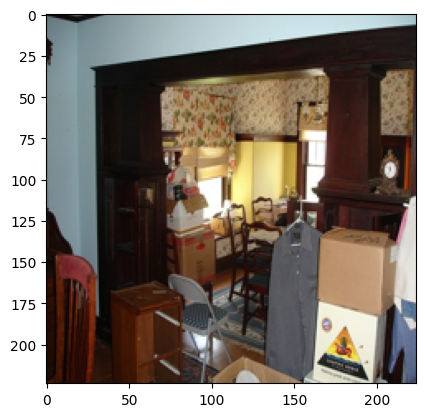

In [9]:
# Check image resizing



img_path, xml_path = train[0]

img = Image.open(img_path).convert("RGB")
print("original size:", img.size)

img = img.resize((224, 224))
img = np.array(img, dtype="float32") / 255.0

print("new shape:", img.shape)
print("min:", img.min(), "max:", img.max())

plt.imshow(img)
plt.show()

## Resizing Images with LetterBox

In [10]:
# Resize images without changing their aspect ratio

def letterbox_image(img, size = 224):
    W, H = img.size
    scale = size / max(W, H)
    new_w, new_h = round(W * scale), round(H * scale)

    resized = img.resize((new_w, new_h))
    canvas = Image.new("RGB", (size, size), (0, 0, 0))

    pad_x = (size - new_w) // 2
    pad_y = (size - new_h) // 2
    canvas.paste(resized, (pad_x, pad_y))

    return np.array(canvas, dtype = "uint8"), (new_w, new_h, pad_x, pad_y)

shape: (224, 224, 3)
Info (new_w, new_h, pad_x, pad_y): (224, 168, 0, 28)


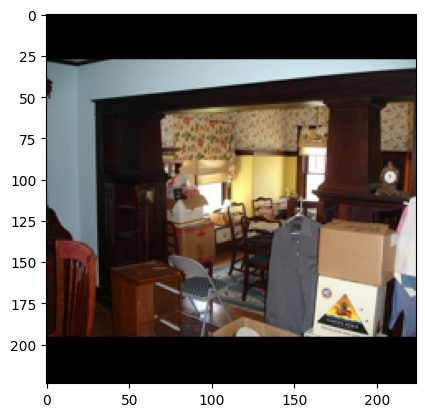

In [11]:
img = Image.open(img_path).convert("RGB")
padded, info = letterbox_image(img)

print("shape:", padded.shape)
print("Info (new_w, new_h, pad_x, pad_y):", info)

plt.imshow(padded)
plt.show()

## Updating Bounding Boxes

In [12]:
# Update boxes for the letterboxed image

def fix_boxes(boxes, info, size = 224):
    new_w, new_h, pad_x, pad_y = info
    fixed = boxes.copy()
    fixed[:, 0] = (boxes[:, 0] * new_w + pad_x) / size
    fixed[:, 1] = (boxes[:, 1] * new_h + pad_y) / size
    fixed[:, 2] = boxes[:, 2] * new_w / size
    fixed[:, 3] = boxes[:, 3] * new_h / size
    return fixed

## Checking the Resized Boxes

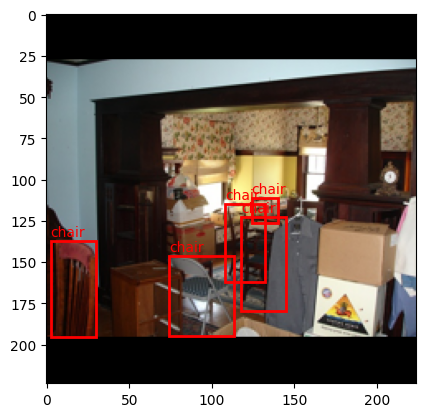

In [14]:
boxes, labels = parse_voc_xml(xml_path)

boxes = fix_boxes(boxes, info)

fig, ax = plt.subplots()
ax.imshow(padded)

for (cx, cy, w, h), c in zip(boxes, labels):
    x1 = (cx - w / 2) * 224
    y1 = (cy - h / 2) * 224
    ax.add_patch(plt.Rectangle((x1, y1), w * 224, h * 224,
                              fill = False, color = "red", linewidth = 2))
    ax.text(x1, y1 - 3, CLASSES[c], color = "red")

plt.show()

## Loading One Sample

In [15]:
# Load an image and prepare its target

def load_sample(img_path, xml_path):
    img = Image.open(img_path).convert("RGB")
    padded, info = letterbox_image(img)
    boxes, labels = parse_voc_xml(xml_path)
    boxes = fix_boxes(boxes, info)
    target = encode_target(boxes, labels)
    return padded, target
    

In [16]:
image, target = load_sample(*train[0])

print("image:", image.shape)
print("target:", target.shape)
print("squares with an object:", int(target[:, :, 0].sum()))

image: (224, 224, 3)
target: (14, 14, 25)
squares with an object: 5


## Resizing and Saving the Images

In [17]:
# Save the resized images and annotations

OUT = "/kaggle/working/cache"
os.makedirs(OUT, exist_ok = True)

def cache_split(pairs, name):
    images = np.zeros((len(pairs), 224, 224, 3), dtype = "uint8")
    all_boxes, all_labels = [], []

    for i, (img_path, xml_path) in enumerate(tqdm(pairs)):
        img = Image.open(img_path).convert("RGB")
        padded, info = letterbox_image(img)
        boxes, labels = parse_voc_xml(xml_path)
        boxes = fix_boxes(boxes, info)

        images[i] = padded
        all_boxes.append(boxes)
        all_labels.append(labels)

    np.save(f"{OUT}/{name}_images.npy", images)
    with open(f"{OUT}/{name}_boxes.pkl", "wb") as f:
        pickle.dump((all_boxes, all_labels), f)

    print(name, "done:", images.shape)


cache_split(val, "val")
cache_split(test, "test")
cache_split(train, "train")


100%|██████████| 3311/3311 [07:44<00:00,  7.13it/s]


val done: (3311, 224, 224, 3)


100%|██████████| 4952/4952 [11:30<00:00,  7.17it/s]


test done: (4952, 224, 224, 3)


100%|██████████| 13240/13240 [31:06<00:00,  7.09it/s] 


train done: (13240, 224, 224, 3)


## Loading the Cached Data

In [18]:
# Load the cached arrays and annotations

train_images = np.load("/kaggle/working/cache/train_images.npy")
val_images = np.load("/kaggle/working/cache/val_images.npy")
test_images = np.load("/kaggle/working/cache/test_images.npy")

with open("/kaggle/working/cache/train_boxes.pkl", "rb") as f:
    train_boxes, train_labels = pickle.load(f)
with open("/kaggle/working/cache/val_boxes.pkl", "rb") as f:
    val_boxes, val_labels = pickle.load(f)
with open("/kaggle/working/cache/test_boxes.pkl", "rb") as f:
    test_boxes, test_labels = pickle.load(f)

print(train_images.shape, val_images.shape, test_images.shape)
print(len(train_images), len(val_images), len(test_boxes))

(13240, 224, 224, 3) (3311, 224, 224, 3) (4952, 224, 224, 3)
13240 3311 4952


## Checking an Image with Boxes

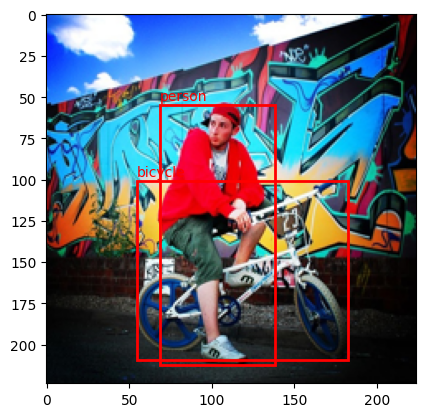

In [19]:
# View one image with its bounding boxes

i = 333

fig, ax = plt.subplots()
ax.imshow(train_images[i])

for (cx, cy, w, h), c in zip(train_boxes[i], train_labels[i]):
    x1 = (cx - w / 2) * 224
    y1 = (cy - h / 2) * 224
    ax.add_patch(plt.Rectangle((x1, y1), w * 224, h * 224,
                              fill = False, color = "red", linewidth = 2))
    ax.text(x1, y1-3, CLASSES[c], color = "red")

plt.show()

## Creating Batches and Augmentations

In [20]:
# Prepare batches and apply training augmentations

import cv2

BATCH = 32

def random_crop(image, boxes, labels):
    # image: 224x224x3 float32 (0-255), boxes: normalized (cx, cy, w, h)
    scale = np.random.uniform(0.6, 1.0)      # crop size as fraction of image
    x0 = np.random.uniform(0, 1 - scale)
    y0 = np.random.uniform(0, 1 - scale)

    # center format -> corner format
    x1 = boxes[:, 0] - boxes[:, 2] / 2
    y1 = boxes[:, 1] - boxes[:, 3] / 2
    x2 = boxes[:, 0] + boxes[:, 2] / 2
    y2 = boxes[:, 1] + boxes[:, 3] / 2
    area_before = (x2 - x1) * (y2 - y1)

    # shift into crop coordinates and clip to the crop window
    nx1 = np.clip(x1 - x0, 0, scale)
    ny1 = np.clip(y1 - y0, 0, scale)
    nx2 = np.clip(x2 - x0, 0, scale)
    ny2 = np.clip(y2 - y0, 0, scale)
    area_after = (nx2 - nx1) * (ny2 - ny1)

    # keep boxes that are still at least 40% visible
    keep = area_after > 0.4 * area_before
    if not keep.any():
        return image, boxes, labels          # nothing survives, skip the crop

    # rescale to 0-1 relative to the crop, back to center format
    nx1, nx2 = nx1[keep] / scale, nx2[keep] / scale
    ny1, ny2 = ny1[keep] / scale, ny2[keep] / scale
    new_boxes = np.stack([(nx1 + nx2) / 2, (ny1 + ny2) / 2,
                          nx2 - nx1, ny2 - ny1], axis=1).astype("float32")
    new_labels = np.asarray(labels)[keep]

    # crop the image and resize back to 224x224
    h, w = image.shape[:2]
    px1, py1 = int(x0 * w), int(y0 * h)
    px2, py2 = int((x0 + scale) * w), int((y0 + scale) * h)
    crop = image[py1:py2, px1:px2]
    image = cv2.resize(crop, (w, h))

    return image, new_boxes, new_labels


def make_dataset(images, boxes_list, labels_list, training):

    def get_sample(i):
        i = int(i)
        image = images[i].astype("float32")
        boxes = boxes_list[i].copy()
        labels = labels_list[i]

        if training:
            if np.random.rand() < 0.5:
                image = image[:, ::-1, :]
                boxes[:, 0] = 1.0 - boxes[:, 0]
            if np.random.rand() < 0.5:
                image, boxes, labels = random_crop(image, boxes, labels)
            image = np.clip(image * np.random.uniform(0.8, 1.2), 0, 255)
        image = image / 255.0
        target = encode_target(boxes, labels)
        return np.ascontiguousarray(image, dtype = "float32"), target

    def tf_get(i):
        image, target = tf.numpy_function(get_sample, [i], [tf.float32, tf.float32])
        image.set_shape((224, 224, 3))
        target.set_shape((GRID, GRID, 25))
        return image, target

    ds = tf.data.Dataset.from_tensor_slices(np.arange(len(images)))
    if training:
        ds = ds.shuffle(len(images))
    ds = ds.map(tf_get, num_parallel_calls = tf.data.AUTOTUNE)
    ds = ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
    return ds

## Creating the Datasets

In [21]:
# Create train, validation and test datasets

train_ds = make_dataset(train_images, train_boxes, train_labels, training = True)
val_ds = make_dataset(val_images, val_boxes, val_labels, training = False)
test_ds = make_dataset(test_images, test_boxes, test_labels, training = False)

images, targets = next(iter(train_ds))
print(images.shape, targets.shape)
print("pixel range:", float(images.numpy().min()), float(images.numpy().max()))

(32, 224, 224, 3) (32, 14, 14, 25)
pixel range: 0.0 1.0


In [22]:
# Check the box coordinates

print(train_boxes[0])
print(train_boxes[0].min(), train_boxes[0].max())

[[0.587      0.6750001  0.122      0.25599998]
 [0.418      0.76100004 0.176      0.21599999]
 [0.07199999 0.74300003 0.124      0.26      ]
 [0.536      0.61800003 0.108      0.21000001]
 [0.58900005 0.531      0.07       0.068     ]]
0.068 0.76100004


## Loss Function

In [23]:
# Define the residual block

def detection_loss(y_true, y_pred):
    obj = y_true[..., 0:1]
    noobj = 1.0 - obj

    true_xy = y_true[..., 1:3]
    true_wh = y_true[..., 3:5]
    true_cls = y_true[..., 5:]

    pred_xy = tf.sigmoid(y_pred[..., 1:3])
    pred_wh = tf.sigmoid(y_pred[..., 3:5])
    pred_cls = y_pred[..., 5:]

    # 1. Box loss
    xy_loss = tf.reduce_sum(obj * tf.square(true_xy - pred_xy), axis = [1, 2, 3])

    wh_loss = tf.reduce_sum(obj * tf.square(true_wh - pred_wh), axis=[1, 2, 3])

    # 2. Object loss
    bce = tf.nn.sigmoid_cross_entropy_with_logits(labels = obj, logits = y_pred[..., 0:1])
    obj_loss = tf.reduce_sum(obj * bce, axis = [1, 2, 3]) + 0.5 * tf.reduce_sum(noobj * bce, axis = [1, 2, 3])

    # 3. Class loss
    ce = tf.nn.softmax_cross_entropy_with_logits(labels = true_cls, logits = pred_cls)
    cls_loss = tf.reduce_sum(obj[..., 0] * ce, axis = [1, 2])

    return 5.0 * (xy_loss + wh_loss) + obj_loss + cls_loss

## Residual Block

In [24]:
# Compile and train the final model


def residual_block(x, filters, stride=1):
    shortcut = x

    # Main branch
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=stride,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=1,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)

    # Projection shortcut when dimensions change
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters,
            kernel_size=1,
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = layers.BatchNormalization()(shortcut)

    # Residual connection
    x = layers.Add()([x, shortcut])
    x = layers.ReLU()(x)

    return x


## Building the Final CNN

In [25]:
# Decode predictions, apply NMS and display boxes


def build_model_v2(dropout=0.2):

    inputs = tf.keras.Input(
        shape=(224, 224, 3),
        name="image_input"
    )

    # --------------------------------------------------
    # Stem: 224 -> 112
    # --------------------------------------------------
    x = layers.Conv2D(
        32,
        kernel_size=3,
        strides=2,
        padding="same",
        use_bias=False
    )(inputs)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # --------------------------------------------------
    # Stage 1: 112 -> 56
    # --------------------------------------------------
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 64)

    # --------------------------------------------------
    # Stage 2: 56 -> 28
    # --------------------------------------------------
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128)

    # --------------------------------------------------
    # Stage 3: 28 -> 14
    # --------------------------------------------------
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256)
    x = residual_block(x, 256)

    # --------------------------------------------------
    # Stage 4: Preserve 14 x 14
    # --------------------------------------------------
    x = residual_block(x, 384)
    x = residual_block(x, 384)

    # --------------------------------------------------
    # Detection Head
    # --------------------------------------------------
    x = layers.Conv2D(
        256,
        kernel_size=3,
        padding="same",
        use_bias=False
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Dropout(dropout)(x)

    # 25 outputs per grid cell:
    # 1 objectness + 4 box values + 20 classes
    initial_bias = [-2.0] + [0.0] * 24

    outputs = layers.Conv2D(
        25,
        kernel_size=1,
        padding="same",
        activation=None,
        bias_initializer=tf.keras.initializers.Constant(
            initial_bias
        ),
        name="grid_output"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="Scratch_Detector_V2"
    )

    return model


## Training the Model

In [26]:
# Create a fresh Model 2 using the improved residual architecture
model2 = build_model_v2(dropout=0.2)

model2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001,
        global_clipnorm=10.0
    ),
    loss=detection_loss
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/model2_scratch.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )
]

# Verify output and target shapes
images, targets = next(iter(train_ds))

predictions = model2(images, training=False)

print("Images shape:", images.shape)
print("Targets shape:", targets.shape)
print("Predictions shape:", predictions.shape)

print(
    "Starting loss:",
    float(tf.reduce_mean(detection_loss(targets, predictions)))
)

# Train on the complete training dataset
start = time.time()

history = model2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks
)

train_time = time.time() - start

print("Training time (minutes):", round(train_time / 60, 1))

Images shape: (32, 224, 224, 3)
Targets shape: (32, 14, 14, 25)
Predictions shape: (32, 14, 14, 25)
Starting loss: 28.755611419677734
Epoch 1/40
414/414 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - loss: 22.8006
Epoch 1: val_loss improved from None to 21.87765, saving model to /kaggle/working/model2_scratch.keras

Epoch 1: finished saving model to /kaggle/working/model2_scratch.keras
414/414 ━━━━━━━━━━━━━━━━━━━━ 112s 187ms/step - loss: 20.5533 - val_loss: 21.8776 - learning_rate: 1.0000e-04
Epoch 2/40
414/414 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - loss: 18.2433
Epoch 2: val_loss improved from 21.87765 to 18.28613, saving model to /kaggle/working/model2_scratch.keras

Epoch 2: finished saving model to /kaggle/working/model2_scratch.keras
414/414 ━━━━━━━━━━━━━━━━━━━━ 55s 132ms/step - loss: 18.0759 - val_loss: 18.2861 - learning_rate: 1.0000e-04
Epoch 3/40
414/414 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - loss: 17.2205
Epoch 3: val_loss improved from 18.28613 to 18.00622, saving model to /kaggle/working

In [45]:
model2.summary()

Model: "Scratch_Detector_V2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        864 │ image_input[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 56, 56,    │     18,432 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 56, 56,    │     36,864 │ re_lu_1[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 56, 56,    │      2,048 │ re_lu[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 56, 56,    │          0 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     36,864 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │     36,864 │ re_lu_3[0][0]   

 Total params: 29,405,293 (112.17 MB)

 Trainable params: 9,798,457 (37.38 MB)

 Non-trainable params: 9,920 (38.75 KB)

 Optimizer params: 19,596,916 (74.76 MB)

## Checking Prediction Confidence

In [27]:
# Get one validation batch
x, y_true = next(iter(val_ds))

# Predict using the best restored model weights
y_pred = model2(x, training=False).numpy()

# Objectness confidence
objectness_scores = tf.sigmoid(y_pred[..., 0]).numpy()

print("Maximum confidence:", objectness_scores.max())
print("Mean confidence:", objectness_scores.mean())

for threshold in [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]:
    count = np.sum(objectness_scores > threshold)
    print(f"Threshold {threshold}: {count} predictions")

Maximum confidence: 0.94535357
Mean confidence: 0.020916298
Threshold 0.01: 1390 predictions
Threshold 0.05: 614 predictions
Threshold 0.1: 354 predictions
Threshold 0.2: 169 predictions
Threshold 0.3: 94 predictions
Threshold 0.5: 31 predictions


## Visualizing Predictions

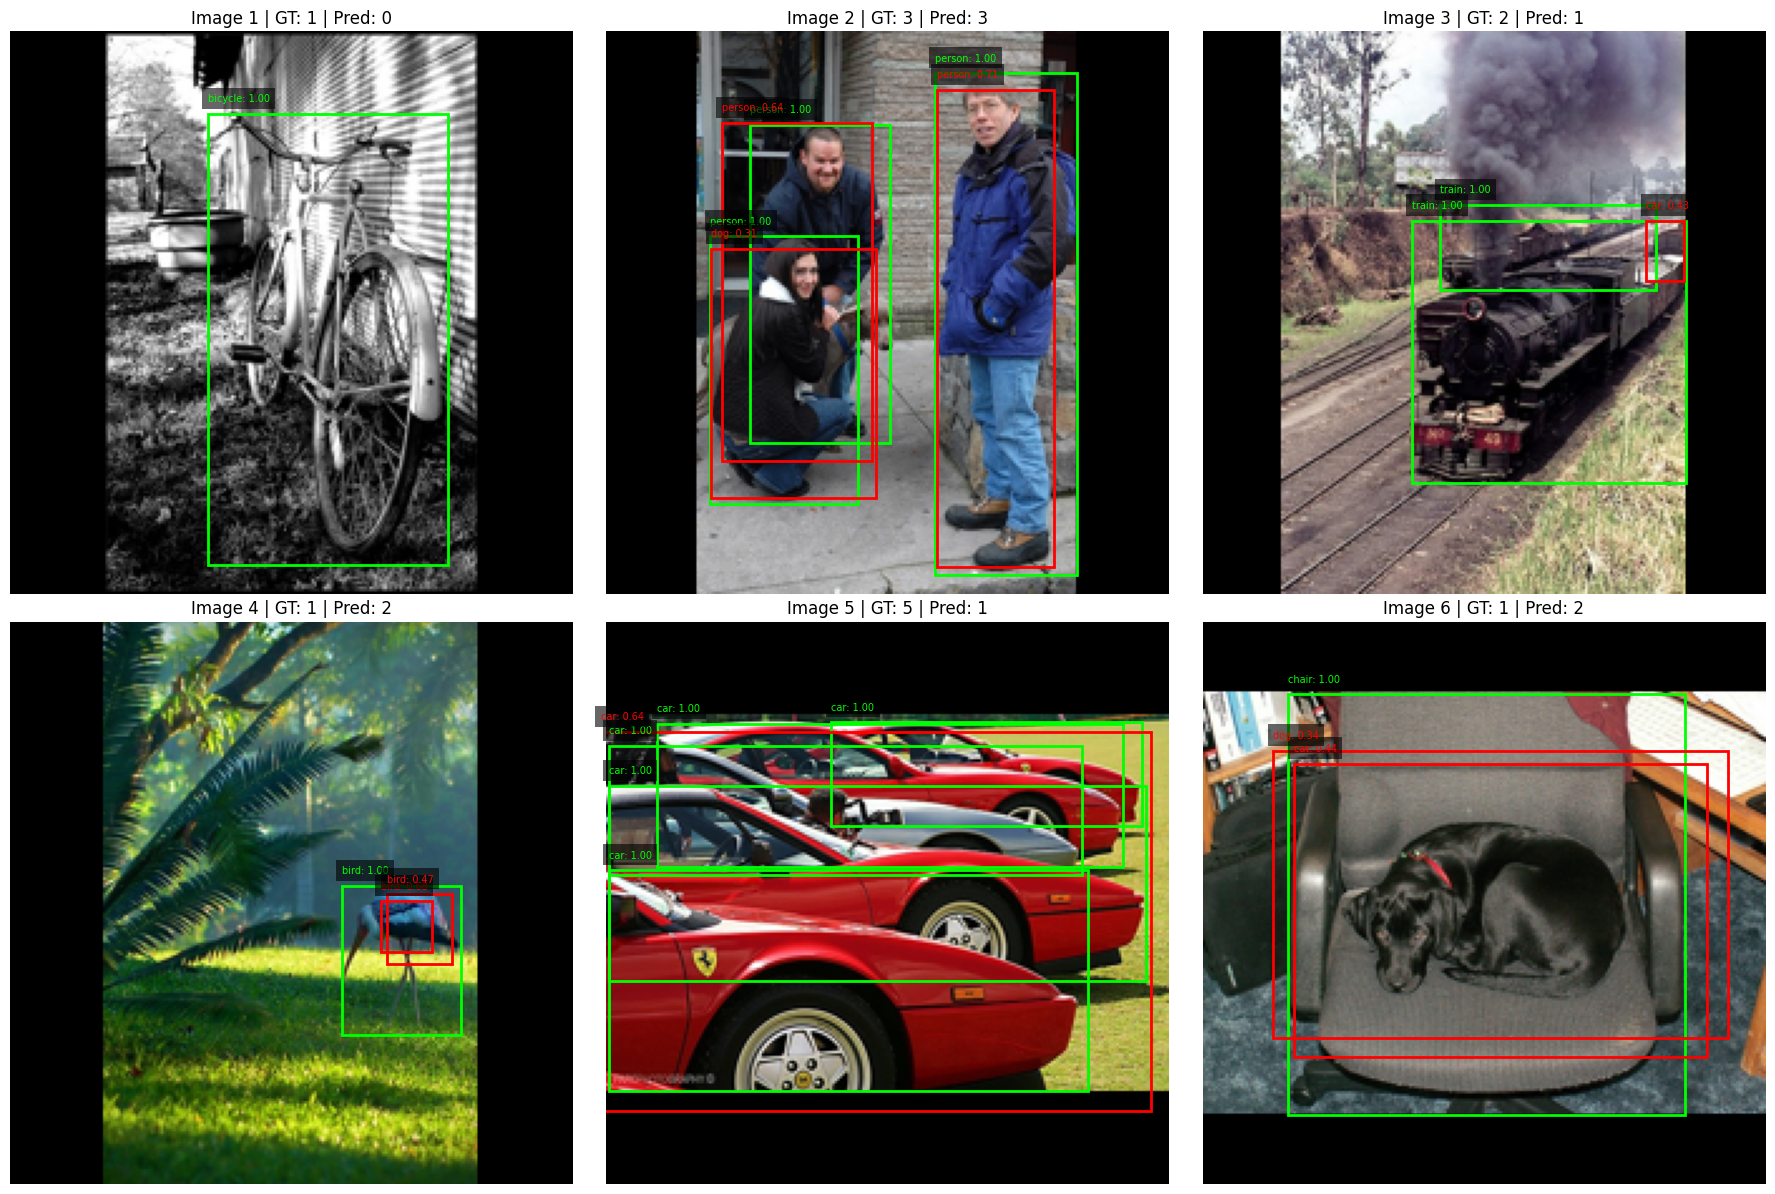

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf

# -----------------------------
# Configuration
# -----------------------------
S = 14
CELL_RELATIVE = True
THRESH = 0.3
NUM_IMAGES = 6

# Pascal VOC class names
class_names = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]


# -----------------------------
# Decode target/prediction
# -----------------------------
def decode(t, is_pred):
    if is_pred:
        obj = tf.sigmoid(t[..., 0]).numpy()
        xy = tf.sigmoid(t[..., 1:3]).numpy()
        wh = tf.sigmoid(t[..., 3:5]).numpy()
        cls = tf.nn.softmax(t[..., 5:]).numpy()
    else:
        obj = t[..., 0]
        xy = t[..., 1:3]
        wh = t[..., 3:5]
        cls = t[..., 5:]

    detections = []

    for r in range(S):
        for c in range(S):

            confidence = float(obj[r, c])

            if confidence > THRESH:

                x, y = xy[r, c]

                if CELL_RELATIVE:
                    cx = (c + x) / S
                    cy = (r + y) / S
                else:
                    cx, cy = x, y

                w, h = wh[r, c]

                class_id = int(np.argmax(cls[r, c]))

                detections.append(
                    (
                        cx, cy, w, h,
                        class_id, confidence
                    )
                )

    return detections


# -----------------------------
# Non-Maximum Suppression
# -----------------------------
def nms(detections, iou_threshold=0.5):

    if not detections:
        return []

    detections = sorted(
        detections,
        key=lambda x: x[5],
        reverse=True
    )

    selected = []

    while detections:

        best = detections.pop(0)
        selected.append(best)

        remaining = []

        for det in detections:

            # Compare boxes only if they belong to the same class
            if det[4] != best[4]:
                remaining.append(det)
                continue

            # Convert center format to corner format
            x1 = best[0] - best[2] / 2
            y1 = best[1] - best[3] / 2
            x2 = best[0] + best[2] / 2
            y2 = best[1] + best[3] / 2

            xx1 = det[0] - det[2] / 2
            yy1 = det[1] - det[3] / 2
            xx2 = det[0] + det[2] / 2
            yy2 = det[1] + det[3] / 2

            # Intersection
            inter_x1 = max(x1, xx1)
            inter_y1 = max(y1, yy1)
            inter_x2 = min(x2, xx2)
            inter_y2 = min(y2, yy2)

            inter_w = max(0, inter_x2 - inter_x1)
            inter_h = max(0, inter_y2 - inter_y1)

            intersection = inter_w * inter_h

            area1 = best[2] * best[3]
            area2 = det[2] * det[3]

            union = area1 + area2 - intersection

            iou = intersection / (union + 1e-8)

            if iou < iou_threshold:
                remaining.append(det)

        detections = remaining

    return selected


# -----------------------------
# Draw bounding boxes
# -----------------------------
def draw(ax, detections, color):

    for cx, cy, w, h, class_id, confidence in detections:

        # Convert normalized coordinates to image pixels
        image_w = 224
        image_h = 224

        x = (cx - w / 2) * image_w
        y = (cy - h / 2) * image_h

        box_w = w * image_w
        box_h = h * image_h

        rect = patches.Rectangle(
            (x, y),
            box_w,
            box_h,
            linewidth=2,
            edgecolor=color,
            facecolor="none"
        )

        ax.add_patch(rect)

        label = f"{class_names[class_id]}: {confidence:.2f}"

        ax.text(
            x,
            max(y - 5, 0),
            label,
            color=color,
            fontsize=7,
            bbox=dict(
                facecolor="black",
                alpha=0.6,
                edgecolor="none"
            )
        )


# -----------------------------
# Visualize validation images
# -----------------------------
x, y_true = next(iter(val_ds))

# Use the fully trained model
y_pred = model2(x, training=False).numpy()

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 12)
)

axes = axes.flatten()

for i in range(NUM_IMAGES):

    # Display image
    image = x[i].numpy()

    # If image is normalized to [0, 1], display directly
    axes[i].imshow(np.clip(image, 0, 1))

    # Ground-truth boxes
    true_detections = decode(
        y_true[i].numpy(),
        is_pred=False
    )

    draw(
        axes[i],
        true_detections,
        color="lime"
    )

    # Predicted boxes with NMS
    predicted_detections = decode(
        y_pred[i],
        is_pred=True
    )

    predicted_detections = nms(
        predicted_detections,
        iou_threshold=0.5
    )

    draw(
        axes[i],
        predicted_detections,
        color="red"
    )

    axes[i].set_title(
        f"Image {i + 1} | "
        f"GT: {len(true_detections)} | "
        f"Pred: {len(predicted_detections)}"
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Checking Precision and Recall

In [52]:
import numpy as np
import tensorflow as tf

IOU_TH = 0.5
SCORE_TH = 0.3
S = 14

TP, FP, FN = 0, 0, 0
aps = []

def iou(a, b):
    x1, y1 = np.maximum(a[:2], b[:2])
    x2, y2 = np.minimum(a[2:], b[2:])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = (a[2]-a[0]) * (a[3]-a[1])
    area_b = (b[2]-b[0]) * (b[3]-b[1])
    return inter / (area_a + area_b - inter + 1e-8)

ious = []

for images, targets in val_ds:
    preds = model2(images, training=False).numpy()

    for p, t in zip(preds, targets.numpy()):
        # Ground-truth boxes
        gt = []
        for r in range(S):
            for c in range(S):
                if t[r,c,0] == 1:
                    x, y = t[r,c,1:3]
                    w, h = t[r,c,3:5]
                    gt.append([(c+x)/S-w/2, (r+y)/S-h/2,
                               (c+x)/S+w/2, (r+y)/S+h/2,
                               int(np.argmax(t[r,c,5:]))])

        # Predicted boxes
        pr = []
        obj = tf.sigmoid(p[...,0]).numpy()
        xy = tf.sigmoid(p[...,1:3]).numpy()
        wh = tf.sigmoid(p[...,3:5]).numpy()
        cls = tf.nn.softmax(p[...,5:]).numpy()

        for r in range(S):
            for c in range(S):
                cid = int(np.argmax(cls[r,c]))
                score = obj[r,c] * cls[r,c,cid]

                if score >= SCORE_TH:
                    x, y = xy[r,c]
                    w, h = wh[r,c]
                    pr.append([(c+x)/S-w/2, (r+y)/S-h/2,
                               (c+x)/S+w/2, (r+y)/S+h/2,
                               cid, score])

        pr = nms(pr, iou_threshold=0.5)
        matched = set()

        for box in pr:
            candidates = [
                (iou(box[:4], g[:4]), j)
                for j, g in enumerate(gt)
                if g[4] == box[4] and j not in matched
            ]

            best = max(candidates, default=(0, -1))

            if best[0] >= IOU_TH:
                TP += 1
                ious.append(best[0])
                matched.add(best[1])
            else:
                FP += 1

        FN += len(gt) - len(matched)

precision = TP / (TP + FP + 1e-8)
recall = TP / (TP + FN + 1e-8)

print("Mean IoU of matched detections:", round(float(np.mean(ious)), 3))
print("TP:", TP, "| FP:", FP, "| FN:", FN)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Mean IoU of matched detections: 0.71
TP: 1722 | FP: 1550 | FN: 7462
Precision: 0.5263
Recall: 0.1875


## Checking Predictions after NMS

In [30]:
S = 14
SCORE_TH = 0.001

gts, preds = {}, []

for img_id, (images, targets) in enumerate(val_ds):
    outputs = model2.predict(images, verbose=0)

    for b in range(len(images)):
        gt_boxes, pred_boxes = [], []

        # Ground-truth boxes
        for r, c in np.argwhere(targets[b][..., 0] == 1):
            t = targets[b][r, c]
            x, y, w, h = t[1:5]

            gt_boxes.append([
                (c+x-w/2)*224/S,
                (r+y-h/2)*224/S,
                (c+x+w/2)*224/S,
                (r+y+h/2)*224/S,
                np.argmax(t[5:])
            ])

        gts[img_id*len(images)+b] = gt_boxes

        # Predicted boxes
        p = outputs[b]
        obj = tf.sigmoid(p[..., 0]).numpy()
        cls = tf.nn.softmax(p[..., 5:], axis=-1).numpy()

        for r, c in np.argwhere(obj * cls.max(axis=-1) >= SCORE_TH):
            cid = np.argmax(cls[r, c])
            score = obj[r, c] * cls[r, c, cid]

            x, y, w, h = tf.sigmoid(p[r, c, 1:5]).numpy()

            box = [
                (c+x-w/2)*224/S,
                (r+y-h/2)*224/S,
                (c+x+w/2)*224/S,
                (r+y+h/2)*224/S,
                cid,
                score
            ]

            pred_boxes.append(box)

        preds.extend([
            (img_id*len(images)+b, box)
            for box in nms(pred_boxes, 0.5)
        ])

print("Validation images:", len(gts))
print("Ground-truth objects:", sum(len(v) for v in gts.values()))
print("Predictions after NMS:", len(preds))

Validation images: 3296
Ground-truth objects: 9145
Predictions after NMS: 72062


In [50]:
import os, time
x, _ = next(iter(test_ds))
model2(x, training=False)          # warm-up run
t = time.time()
for _ in range(20):
    model2(x, training=False)
dt = (time.time() - t) / 20
print("ms per image:", round(dt / len(x) * 1000, 2), "| FPS:", round(len(x) / dt, 1))

ms per image: 2.09 | FPS: 479.3


## Conclusion – CNN Object Detection from Scratch

* Developed an end-to-end CNN-based object detection model using the PASCAL VOC dataset without transfer learning. The project included dataset preparation, bounding-box preprocessing, target encoding, model architecture design, training, prediction decoding, and non-maximum suppression.

* The model learned to identify and localize objects across multiple classes. However, its detection performance was limited by false-positive predictions, low recall, and localization errors. This experiment provided practical experience in building and evaluating an object detection pipeline from scratch.

# Model 2 - With Transfer Learning(ResNet50 as Backbone)

In [54]:
from tensorflow.keras import layers

def build_resnet_model(dropout = 0.3):
    inputs = tf.keras.Input(shape = (224, 224, 3))

    x = layers.Rescaling(255.0)(inputs)
    x = layers.Lambda(tf.keras.applications.resnet50.preprocess_input)(x)

    base = tf.keras.applications.ResNet50(
        include_top = False, weights = "imagenet", input_shape = (224, 224, 3)
    )
    backbone = tf.keras.Model(base.input, base.get_layer("conv4_block6_out").output)
    backbone.trainable = False
    x = backbone(x, training = False)

    x = layers.Conv2D(512, 3, padding = "same", activation = "relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Conv2D(25, 1)(x)
    return tf.keras.Model(inputs, outputs)

model3 = build_resnet_model()
print(model3.output_shape)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(None, 14, 14, 25)


## Training the Model on New layers with backbone layers freezed

In [55]:
model3.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate = 1e-3, global_clipnorm = 10.0),
    loss = detection_loss
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/model3_phase1.keras", monitor = "val_loss", save_best_only = True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor = "val_loss", factor = 0.5, patience = 2),
    tf.keras.callbacks.EarlyStopping(monitor = "val_loss", patience = 5, restore_best_weights = True),
]

start = time.time()
history1 = model3.fit(train_ds, validation_data = val_ds, epochs = 15, callbacks = callbacks)
phase1_time = time.time() - start
print("phase 1 time (minutes):", round(phase1_time / 60, 1))

Epoch 1/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 80s 158ms/step - loss: 18.7333 - val_loss: 14.3911 - learning_rate: 0.0010
Epoch 2/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 52s 124ms/step - loss: 14.9428 - val_loss: 14.0603 - learning_rate: 0.0010
Epoch 3/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 49s 119ms/step - loss: 14.6085 - val_loss: 13.8055 - learning_rate: 0.0010
Epoch 4/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 49s 119ms/step - loss: 14.3729 - val_loss: 13.9264 - learning_rate: 0.0010
Epoch 5/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 50s 120ms/step - loss: 14.1707 - val_loss: 13.7789 - learning_rate: 0.0010
Epoch 6/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 50s 121ms/step - loss: 14.0322 - val_loss: 13.5318 - learning_rate: 0.0010
Epoch 7/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 50s 120ms/step - loss: 13.9058 - val_loss: 13.4420 - learning_rate: 0.0010
Epoch 8/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 49s 119ms/step - loss: 13.7843 - val_loss: 13.4567 - learning_rate: 0.0010
Epoch 9/15
414/414 ━━━━━━━━━━━━━━━━━━━━ 50s 120ms/step - loss: 13.6572 - val_los

## Unfreezing the ResNet50 layers and Fine-tuning

In [56]:
for layer in model3.layers:
    if isinstance(layer, tf.keras.Model):
        layer.trainable = True

model3.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate = 1e-5, global_clipnorm = 10.0),
    loss = detection_loss
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/model3_phase2.keras", monitor = "val_loss", save_best_only = True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor = "val_loss", factor = 0.5, patience = 3),
    tf.keras.callbacks.EarlyStopping(monitor = "val_loss", patience = 6, restore_best_weights = True),
]

start = time.time()
history2 = model3.fit(train_ds, validation_data = val_ds, epochs = 30, callbacks = callbacks)
phase2_time = time.time() - start
print("phase 2 time (minutes):", round(phase2_time / 60, 1))

Epoch 1/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 218s 398ms/step - loss: 13.2145 - val_loss: 12.9281 - learning_rate: 1.0000e-05
Epoch 2/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 131s 316ms/step - loss: 12.8500 - val_loss: 12.7730 - learning_rate: 1.0000e-05
Epoch 3/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 129s 311ms/step - loss: 12.5331 - val_loss: 12.6147 - learning_rate: 1.0000e-05
Epoch 4/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 129s 312ms/step - loss: 12.3683 - val_loss: 12.5197 - learning_rate: 1.0000e-05
Epoch 5/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 129s 312ms/step - loss: 12.1816 - val_loss: 12.4511 - learning_rate: 1.0000e-05
Epoch 6/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 129s 312ms/step - loss: 12.0121 - val_loss: 12.3695 - learning_rate: 1.0000e-05
Epoch 7/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 129s 312ms/step - loss: 11.8896 - val_loss: 12.2793 - learning_rate: 1.0000e-05
Epoch 8/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 129s 311ms/step - loss: 11.7569 - val_loss: 12.2361 - learning_rate: 1.0000e-05
Epoch 9/30
414/414 ━━━━━━━━━━━━━━━━━━━━ 

In [58]:
import numpy as np
import tensorflow as tf

IOU_TH = 0.5
SCORE_TH = 0.3
S = 14

TP, FP, FN = 0, 0, 0
aps = []

def iou(a, b):
    x1, y1 = np.maximum(a[:2], b[:2])
    x2, y2 = np.minimum(a[2:], b[2:])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = (a[2]-a[0]) * (a[3]-a[1])
    area_b = (b[2]-b[0]) * (b[3]-b[1])
    return inter / (area_a + area_b - inter + 1e-8)

ious = []

for images, targets in val_ds:
    preds = model3(images, training=False).numpy()

    for p, t in zip(preds, targets.numpy()):
        # Ground-truth boxes
        gt = []
        for r in range(S):
            for c in range(S):
                if t[r,c,0] == 1:
                    x, y = t[r,c,1:3]
                    w, h = t[r,c,3:5]
                    gt.append([(c+x)/S-w/2, (r+y)/S-h/2,
                               (c+x)/S+w/2, (r+y)/S+h/2,
                               int(np.argmax(t[r,c,5:]))])

        # Predicted boxes
        pr = []
        obj = tf.sigmoid(p[...,0]).numpy()
        xy = tf.sigmoid(p[...,1:3]).numpy()
        wh = tf.sigmoid(p[...,3:5]).numpy()
        cls = tf.nn.softmax(p[...,5:]).numpy()

        for r in range(S):
            for c in range(S):
                cid = int(np.argmax(cls[r,c]))
                score = obj[r,c] * cls[r,c,cid]

                if score >= SCORE_TH:
                    x, y = xy[r,c]
                    w, h = wh[r,c]
                    pr.append([(c+x)/S-w/2, (r+y)/S-h/2,
                               (c+x)/S+w/2, (r+y)/S+h/2,
                               cid, score])

        pr = nms(pr, iou_threshold=0.5)
        matched = set()

        for box in pr:
            candidates = [
                (iou(box[:4], g[:4]), j)
                for j, g in enumerate(gt)
                if g[4] == box[4] and j not in matched
            ]

            best = max(candidates, default=(0, -1))

            if best[0] >= IOU_TH:
                TP += 1
                ious.append(best[0])
                matched.add(best[1])
            else:
                FP += 1

        FN += len(gt) - len(matched)

precision = TP / (TP + FP + 1e-8)
recall = TP / (TP + FN + 1e-8)

print("Mean IoU of matched detections:", round(float(np.mean(ious)), 3))
print("TP:", TP, "| FP:", FP, "| FN:", FN)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

Mean IoU of matched detections: 0.677
TP: 2133 | FP: 2151 | FN: 7051
Precision: 0.4979
Recall: 0.2323


In [59]:


# inference speed
x, _ = next(iter(test_ds))
model3(x, training=False)              # warm-up run
t = time.time()
for _ in range(20):
    model3(x, training=False)
dt = (time.time() - t) / 20
print("ms per image:", round(dt / len(x) * 1000, 2), "| FPS:", round(len(x) / dt, 1))

# model size (clean copy, no optimizer data)
clean = build_resnet_model()
clean.set_weights(model3.get_weights())
clean.save("/kaggle/working/model3_clean.keras")
print("params:", clean.count_params())
print("Model size (MB):", round(os.path.getsize("/kaggle/working/model3_clean.keras") / 1e6, 1))

ms per image: 5.9 | FPS: 169.5
params: 13321113
Model size (MB): 53.8


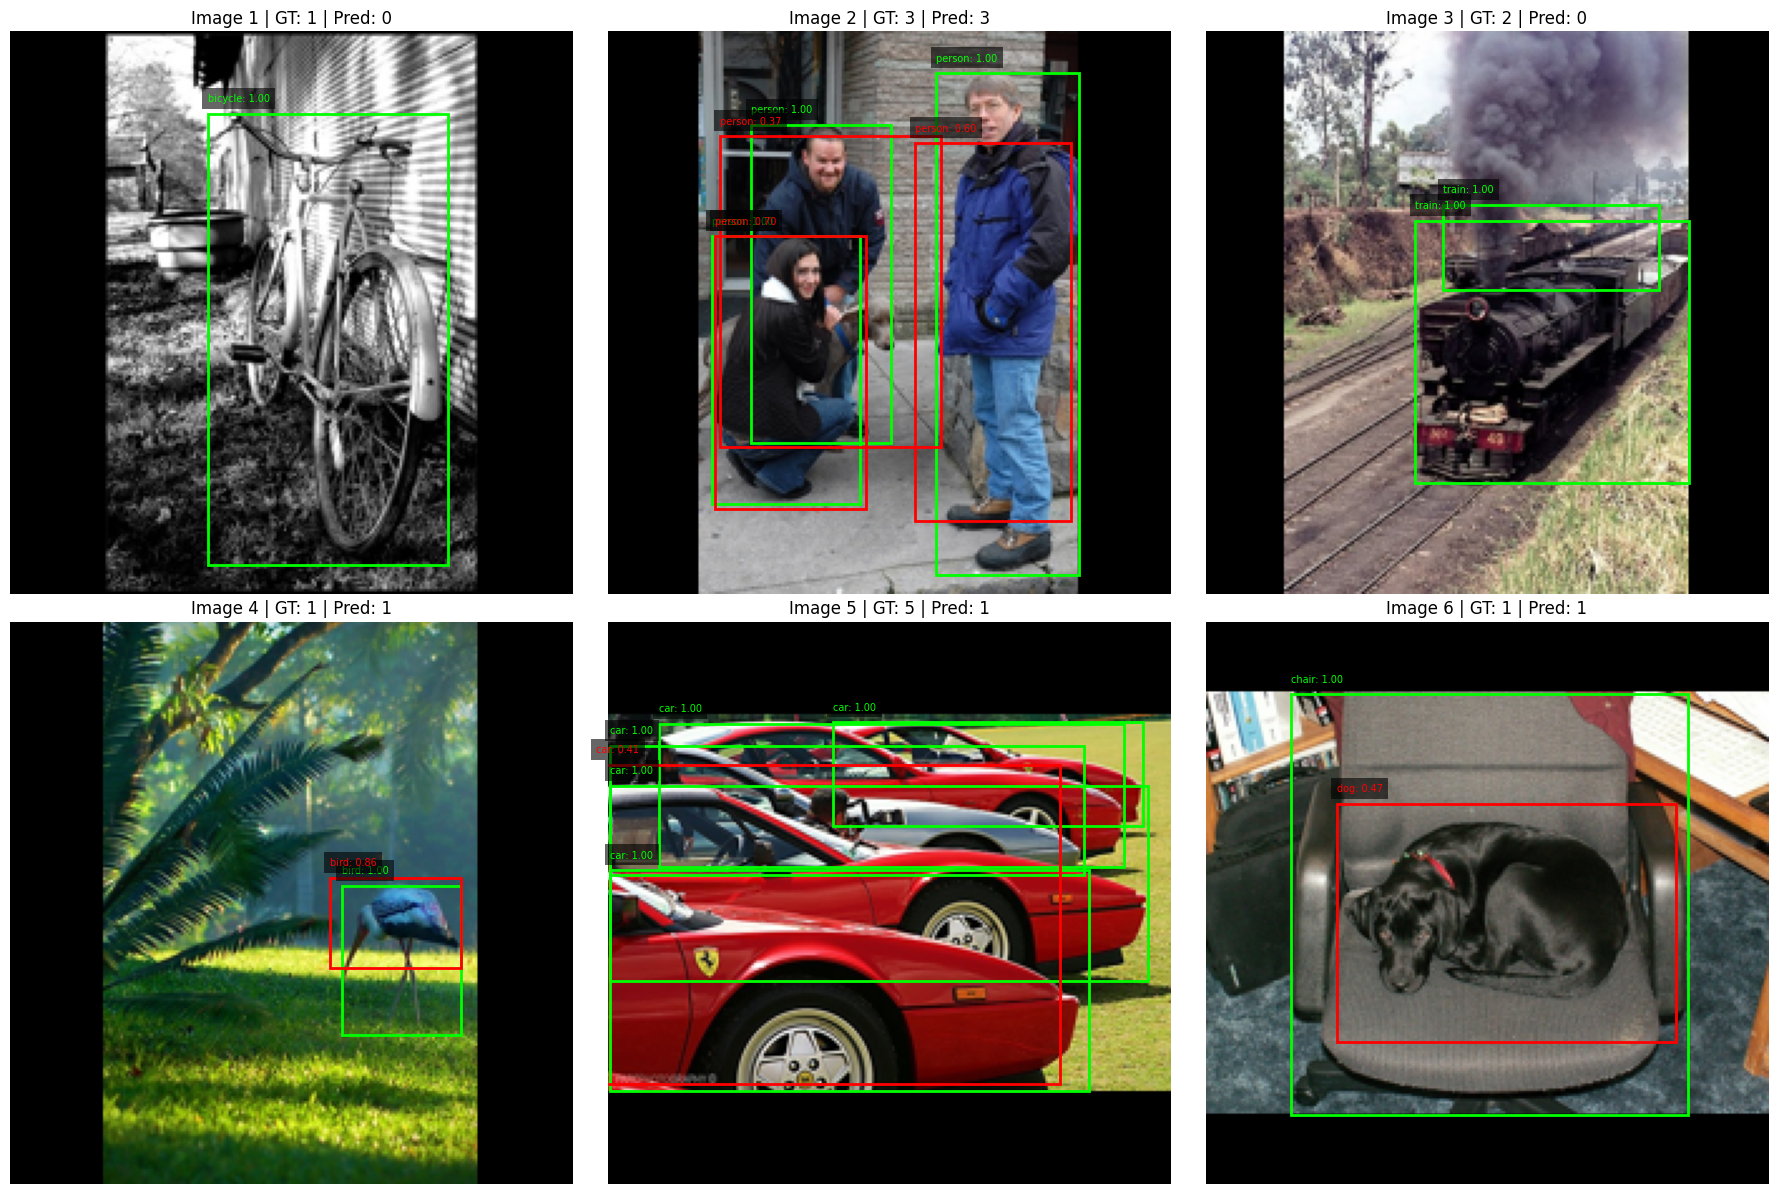

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf

# -----------------------------
# Configuration
# -----------------------------
S = 14
CELL_RELATIVE = True
THRESH = 0.3
NUM_IMAGES = 6

# Pascal VOC class names
class_names = [
    "aeroplane", "bicycle", "bird", "boat", "bottle",
    "bus", "car", "cat", "chair", "cow",
    "diningtable", "dog", "horse", "motorbike", "person",
    "pottedplant", "sheep", "sofa", "train", "tvmonitor"
]


# -----------------------------
# Decode target/prediction
# -----------------------------
def decode(t, is_pred):
    if is_pred:
        obj = tf.sigmoid(t[..., 0]).numpy()
        xy = tf.sigmoid(t[..., 1:3]).numpy()
        wh = tf.sigmoid(t[..., 3:5]).numpy()
        cls = tf.nn.softmax(t[..., 5:]).numpy()
    else:
        obj = t[..., 0]
        xy = t[..., 1:3]
        wh = t[..., 3:5]
        cls = t[..., 5:]

    detections = []

    for r in range(S):
        for c in range(S):

            confidence = float(obj[r, c])

            if confidence > THRESH:

                x, y = xy[r, c]

                if CELL_RELATIVE:
                    cx = (c + x) / S
                    cy = (r + y) / S
                else:
                    cx, cy = x, y

                w, h = wh[r, c]

                class_id = int(np.argmax(cls[r, c]))

                detections.append(
                    (
                        cx, cy, w, h,
                        class_id, confidence
                    )
                )

    return detections


# -----------------------------
# Non-Maximum Suppression
# -----------------------------
def nms(detections, iou_threshold=0.5):

    if not detections:
        return []

    detections = sorted(
        detections,
        key=lambda x: x[5],
        reverse=True
    )

    selected = []

    while detections:

        best = detections.pop(0)
        selected.append(best)

        remaining = []

        for det in detections:

            # Compare boxes only if they belong to the same class
            if det[4] != best[4]:
                remaining.append(det)
                continue

            # Convert center format to corner format
            x1 = best[0] - best[2] / 2
            y1 = best[1] - best[3] / 2
            x2 = best[0] + best[2] / 2
            y2 = best[1] + best[3] / 2

            xx1 = det[0] - det[2] / 2
            yy1 = det[1] - det[3] / 2
            xx2 = det[0] + det[2] / 2
            yy2 = det[1] + det[3] / 2

            # Intersection
            inter_x1 = max(x1, xx1)
            inter_y1 = max(y1, yy1)
            inter_x2 = min(x2, xx2)
            inter_y2 = min(y2, yy2)

            inter_w = max(0, inter_x2 - inter_x1)
            inter_h = max(0, inter_y2 - inter_y1)

            intersection = inter_w * inter_h

            area1 = best[2] * best[3]
            area2 = det[2] * det[3]

            union = area1 + area2 - intersection

            iou = intersection / (union + 1e-8)

            if iou < iou_threshold:
                remaining.append(det)

        detections = remaining

    return selected


# -----------------------------
# Draw bounding boxes
# -----------------------------
def draw(ax, detections, color):

    for cx, cy, w, h, class_id, confidence in detections:

        # Convert normalized coordinates to image pixels
        image_w = 224
        image_h = 224

        x = (cx - w / 2) * image_w
        y = (cy - h / 2) * image_h

        box_w = w * image_w
        box_h = h * image_h

        rect = patches.Rectangle(
            (x, y),
            box_w,
            box_h,
            linewidth=2,
            edgecolor=color,
            facecolor="none"
        )

        ax.add_patch(rect)

        label = f"{class_names[class_id]}: {confidence:.2f}"

        ax.text(
            x,
            max(y - 5, 0),
            label,
            color=color,
            fontsize=7,
            bbox=dict(
                facecolor="black",
                alpha=0.6,
                edgecolor="none"
            )
        )


# -----------------------------
# Visualize validation images
# -----------------------------
x, y_true = next(iter(val_ds))

# Use the fully trained model
y_pred = model3(x, training=False).numpy()

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 12)
)

axes = axes.flatten()

for i in range(NUM_IMAGES):

    # Display image
    image = x[i].numpy()

    # If image is normalized to [0, 1], display directly
    axes[i].imshow(np.clip(image, 0, 1))

    # Ground-truth boxes
    true_detections = decode(
        y_true[i].numpy(),
        is_pred=False
    )

    draw(
        axes[i],
        true_detections,
        color="lime"
    )

    # Predicted boxes with NMS
    predicted_detections = decode(
        y_pred[i],
        is_pred=True
    )

    predicted_detections = nms(
        predicted_detections,
        iou_threshold=0.5
    )

    draw(
        axes[i],
        predicted_detections,
        color="red"
    )

    axes[i].set_title(
        f"Image {i + 1} | "
        f"GT: {len(true_detections)} | "
        f"Pred: {len(predicted_detections)}"
    )

    axes[i].axis("off")

plt.tight_layout()
plt.show()

## Model 3: Transfer Learning with a Pretrained YOLOv8m Detector

### Preparing the dataset in YOLO format

In [61]:
!pip install -q ultralytics

import os
from PIL import Image

names = ["aeroplane","bicycle","bird","boat","bottle","bus","car","cat","chair","cow",
         "diningtable","dog","horse","motorbike","person","pottedplant","sheep","sofa",
         "train","tvmonitor"]

def export(split, images, boxes_list, labels_list):
    img_dir = f"/kaggle/working/yolo_data/{split}/images"
    lbl_dir = f"/kaggle/working/yolo_data/{split}/labels"
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)
    for i in range(len(images)):
        Image.fromarray(images[i].astype("uint8")).save(f"{img_dir}/{i}.jpg")
        with open(f"{lbl_dir}/{i}.txt", "w") as f:
            for (cx, cy, w, h), c in zip(boxes_list[i], labels_list[i]):
                f.write(f"{int(c)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n")

export("train", train_images, train_boxes, train_labels)
export("val", val_images, val_boxes, val_labels)
export("test", test_images, test_boxes, test_labels)

with open("/kaggle/working/yolo_data/data.yaml", "w") as f:
    f.write("path: /kaggle/working/yolo_data\ntrain: train/images\nval: val/images\ntest: test/images\n")
    f.write("names:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(names)))

print(len(os.listdir("/kaggle/working/yolo_data/train/images")), "train images exported")

13240 train images exported


In [1]:
import os
for s in ["train", "val", "test"]:
    p = f"/kaggle/working/yolo_data/{s}/images"
    print(s, len(os.listdir(p)) if os.path.exists(p) else "missing")
print(os.path.exists("/kaggle/working/yolo_data/data.yaml"))

train 13240
val 3311
test 4952
True


In [2]:
import time
from ultralytics import YOLO

yolo = YOLO("yolov8m.pt")

start = time.time()
yolo.train(
    data="/kaggle/working/yolo_data/data.yaml",
    epochs=30,
    imgsz=320,
    batch=16,
    workers=2,
    patience=10,
    project="/kaggle/working/runs",
    name="yolov8m_voc",
)
yolo_time = time.time() - start
print("YOLO training time (minutes):", round(yolo_time / 60, 1))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8m_voc-2, nbs=64, nms=None, opset=None, optimize

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/30      2.32G      1.178      1.602      1.333         42        320: 100% ━━━━━━━━━━━━ 828/828 8.0it/s 1:430.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 104/104 6.3it/s 16.5s0.2s
                   all       3311       9633      0.562      0.444      0.454      0.279

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      2.32G      1.238      1.725      1.381         31        320: 100% ━━━━━━━━━━━━ 828/828 8.1it/s 1:430.2sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 104/104 6.2it/s 16.7s0.2s
                   all       3311       9633      0.575      0.428      0.454      0.282

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/30      2.32G      1.237      1.695      1.382         85        320: 100% ━━━━━━━━━━━━ 828/828 8.1it/s 1:420.2sss
                 Class  

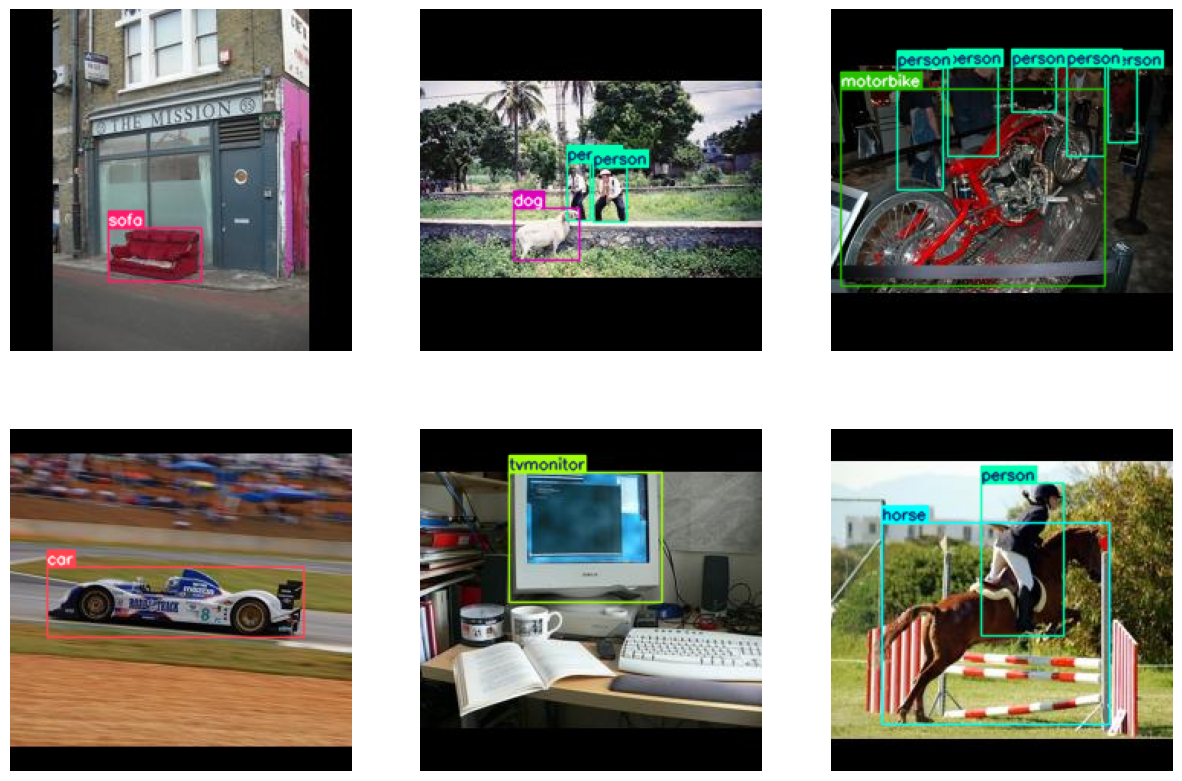

In [14]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import glob
import random

files = random.sample(glob.glob("/kaggle/working/yolo_data/test/images/*.jpg"), 6)

yolo = YOLO("/kaggle/working/runs/yolov8m_voc-2/weights/best.pt")
results = yolo.predict(files, conf=0.3, imgsz=320, verbose=False)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, r in zip(axes.flat, results):
    ax.imshow(r.plot(line_width = 1, conf = False)[..., ::-1])
    ax.axis("off")
plt.show()

In [17]:
import os
w = "/kaggle/working/runs/yolov8m_voc-2/weights"
print(os.path.exists(w), os.listdir(w) if os.path.exists(w) else "")

True ['last.pt', 'best.pt']


In [18]:
import shutil, os
src = "/kaggle/working/runs/yolov8m_voc-2/weights/best.pt"
dst = "/kaggle/working/yolov8m_voc_best.pt"
shutil.copy(src, dst)
print("Model size (MB):", round(os.path.getsize(dst) / 1e6, 1))

Model size (MB): 52.0


In [19]:
import os
for p in ["/kaggle/working/yolov8m_voc_best.pt",
          "/kaggle/working/runs/yolov8m_voc-2/weights/best.pt"]:
    print(p, os.path.exists(p), round(os.path.getsize(p) / 1e6, 1) if os.path.exists(p) else "")

/kaggle/working/yolov8m_voc_best.pt True 52.0
/kaggle/working/runs/yolov8m_voc-2/weights/best.pt True 52.0


In [20]:
import os, shutil

os.makedirs("/kaggle/working/download", exist_ok=True)
for f in ["yolov8m_voc_best.pt", "model_clean.keras", "model3_clean.keras"]:
    shutil.copy(f"/kaggle/working/{f}", "/kaggle/working/download/")

shutil.make_archive("/kaggle/working/my_models", "zip", "/kaggle/working/download")
print(round(os.path.getsize("/kaggle/working/my_models.zip") / 1e6, 1), "MB")

133.7 MB
